# 根据因果图构建结构因果模型

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from semopy import Model
from networkx.drawing import nx_pydot
from sklearn.preprocessing import StandardScaler

## 1. data load

变量数据

In [ ]:
data = pd.read_csv('../data/act_space_travel_features.csv')
# 删除pid列
data = data.drop('pid', axis=1)

data.head()

,area0,area1,area2,area3,cluster0,cluster1,cluster2,cluster3,home_density_0,home_landusemix_0,...,avg_daily_slow_freq2,avg_daily_slow_freq3,avg_daily_tube_dist0,avg_daily_tube_dist1,avg_daily_tube_dist2,avg_daily_tube_dist3,avg_daily_tube_freq0,avg_daily_tube_freq1,avg_daily_tube_freq2,avg_daily_tube_freq3
0,3.147451,3.308764,3.235937,3.434450,1,1,1,1,14.529677,0.618902,...,0.194327,0.197484,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
1,3.404565,3.226078,3.234076,3.220988,1,1,1,1,43.323924,0.731403,...,0.158750,0.162321,6516.841111,6516.841111,3817.016667,3817.016667,0.302222,0.302222,0.35000,0.350000
2,4.208079,4.887184,5.050174,4.030251,2,2,2,2,32.723039,0.688787,...,0.176699,0.215924,10402.511857,6796.715000,6265.231250,7152.244932,0.822429,0.642500,0.76750,1.058679
3,3.530046,3.069087,3.043223,3.064848,2,1,1,1,26.280335,0.665861,...,0.148523,0.155152,7890.081607,12649.038810,8455.105000,7646.896667,0.637765,0.950455,0.50825,0.443111
4,3.458569,5.794304,3.526932,3.464373,2,2,1,2,21.517534,0.764319,...,0.281620,0.225618,0.000000,0.000000,433.860000,433.860000,0.000000,0.000000,0.14000,0.140000


In [5]:
# 对非int类型的列进行标准化
numeric_cols = data.select_dtypes(include=['float64']).columns
scaler = StandardScaler()
data[numeric_cols] = scaler.fit_transform(data[numeric_cols])

data.head()

,area0,area1,area2,area3,cluster0,cluster1,cluster2,cluster3,home_density_0,home_landusemix_0,...,avg_daily_slow_freq2,avg_daily_slow_freq3,avg_daily_tube_dist0,avg_daily_tube_dist1,avg_daily_tube_dist2,avg_daily_tube_dist3,avg_daily_tube_freq0,avg_daily_tube_freq1,avg_daily_tube_freq2,avg_daily_tube_freq3
0,-0.744687,-0.608889,-0.692689,-0.509501,1,1,1,1,-0.885528,-0.611027,...,-0.517820,-0.507870,-0.912620,-0.893552,-0.905257,-0.913905,-1.115959,-1.068603,-1.119792,-1.101909
1,-0.480117,-0.683268,-0.694503,-0.728679,1,1,1,1,0.256275,0.735790,...,-0.696064,-0.701271,0.024985,0.017771,-0.372836,-0.329942,-0.517611,-0.507939,-0.469989,-0.441959
2,0.346698,0.810954,1.074974,0.102256,2,2,2,2,-0.164091,0.225602,...,-0.606139,-0.406450,0.584033,0.056909,-0.031343,0.180311,0.512307,0.123323,0.305134,0.894306
3,-0.350997,-0.824487,-0.880456,-0.889001,2,1,1,1,-0.419569,-0.048852,...,-0.747303,-0.740707,0.222559,0.875306,0.274114,0.255988,0.146706,0.694621,-0.176184,-0.266391
4,-0.424547,1.626939,-0.409164,-0.478776,2,2,1,2,-0.608432,1.129840,...,-0.080472,-0.353129,-0.912620,-0.893552,-0.844739,-0.847529,-1.115959,-1.068603,-0.859871,-0.837929


因果结构

In [6]:
G = nx_pydot.read_dot("supporting_files/graph.dot")

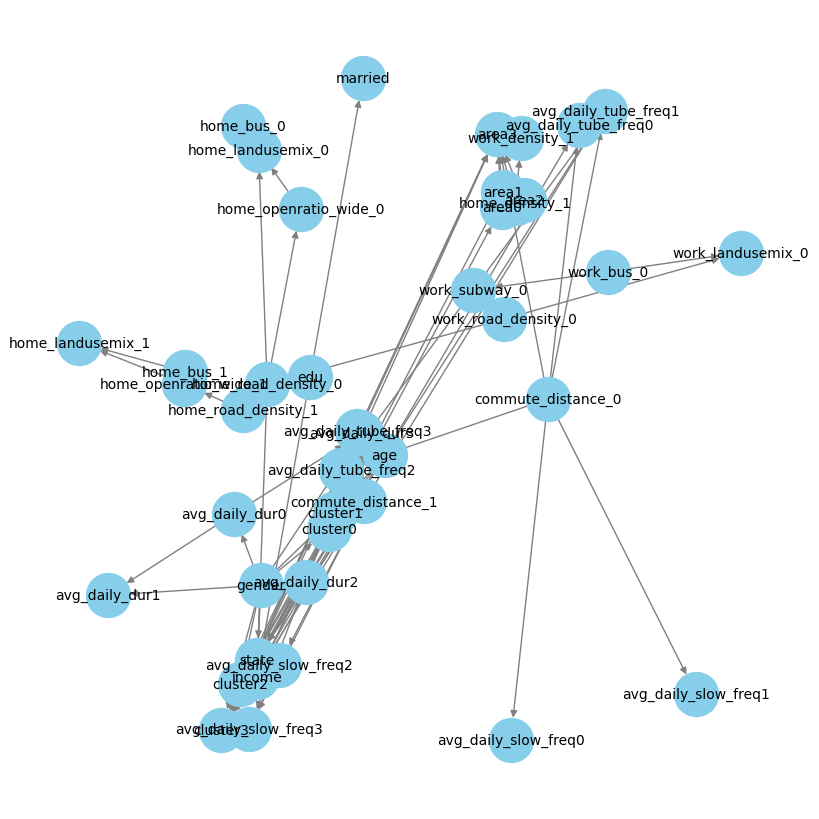

In [16]:
# 可视化因果图结构
plt.figure(figsize=(8, 8))  # 设置图形的大小
pos = nx.spring_layout(G, weight=None)  # 布局方式：spring_layout 根据弹簧模型进行布局

# 绘制节点和边
nx.draw(G, pos, with_labels=True, node_size=1000, node_color='skyblue', font_size=10, edge_color='gray')

plt.show()

## 2. constuct SEM

In [20]:
# 根据因果图构建semopy模型描述
model_spec = []
for u, v in G.edges():
    # 清理节点名称中的特殊符号（如双引号）
    var_from = u.strip('"')
    var_to = v.strip('"')
    model_spec.append(f"{var_to} ~ {var_from}")  # 转换为回归方程
    
model_desc = '\n'.join(model_spec)
print("Generated SEM model syntax:\n", model_desc)

Generated SEM model syntax:
 area1 ~ area0
area2 ~ area0
area3 ~ area0
area2 ~ area1
area3 ~ area1
area3 ~ area2
area0 ~ cluster0
cluster2 ~ cluster0
cluster3 ~ cluster0
income ~ cluster0
state ~ cluster0
area1 ~ cluster1
cluster2 ~ cluster1
cluster3 ~ cluster1
income ~ cluster1
cluster3 ~ cluster2
home_landusemix_0 ~ home_road_density_0
home_openratio_wide_0 ~ home_road_density_0
home_road_density_1 ~ home_road_density_0
income ~ home_road_density_0
home_landusemix_0 ~ home_openratio_wide_0
home_landusemix_0 ~ home_bus_0
home_road_density_0 ~ work_road_density_0
work_landusemix_0 ~ work_road_density_0
avg_daily_tube_freq1 ~ work_subway_0
avg_daily_tube_freq2 ~ work_subway_0
work_landusemix_0 ~ work_bus_0
work_subway_0 ~ work_bus_0
area3 ~ commute_distance_0
avg_daily_slow_freq0 ~ commute_distance_0
avg_daily_slow_freq1 ~ commute_distance_0
avg_daily_tube_freq0 ~ commute_distance_0
avg_daily_tube_freq1 ~ commute_distance_0
avg_daily_tube_freq2 ~ commute_distance_0
area3 ~ home_density_

In [23]:
# 创建并拟合模型
model = Model(model_desc)
res = model.fit(data)
print(res)

Name of objective: MLW
Optimization method: SLSQP
Optimization successful.
Optimization terminated successfully
Objective value: 14.410
Number of iterations: 16
Params: 0.430 0.283 0.089 0.404 0.000 0.111 0.522 -0.057 0.060 -0.059 0.049 0.025 0.050 0.263 0.136 0.365 0.709 -0.053 0.000 -0.039 0.157 -0.115 0.188 0.053 0.178 0.414 0.141 -0.024 -0.011 -0.001 0.056 0.090 -0.106 -0.063 -0.008 -0.001 -0.000 0.033 0.025 0.119 0.548 -0.016 0.096 0.010 0.087 0.139 -0.202 0.245 -0.338 0.536 0.389 0.263 0.374 0.026 0.030 0.016 -0.039 0.855 0.521 0.235 -0.127 0.452 -0.246 -0.211 0.410 -0.153 0.282 -0.342 -0.231 0.272 0.392 -0.080 0.209 0.668 -0.513 -0.367 -0.000 0.829 0.583 -0.034 0.981 -0.023 -0.052 -0.029 -0.040 -0.196 -0.053 0.837 -0.191 0.201 1.022 1.350 1.144 0.777 1.034 0.536 1.034 0.557 0.998 1.008 1.034 0.544 0.928 0.539 0.978 0.491 1.414 1.112 1.374 1.934 0.915 0.930 0.966 0.964 0.942 0.848 0.757 1.011 0.876 0.987 0.849 0.928


In [26]:
ins = model.inspect()

In [30]:
ins.to_csv('results/sem_res1.csv', index=False)